In [2]:
import numpy as np
import time
from scipy.linalg import expm
import scipy as sy
import matplotlib.pyplot as plt
from matplotlib import colors
import matplotlib as mpl
from itertools import combinations

import numpy as np
# import qiskit
# from qiskit import QuantumCircuit, Aer, execute
# from qiskit.circuit import Parameter
# from qiskit.algorithms.optimizers import COBYLA
# from qiskit.quantum_info import state_fidelity
# from qiskit.algorithms import VQE
# from qiskit.opflow import StateFn, CircuitStateFn

sigma_0 = np.array([[1., 0.], [0., 1.]], dtype='complex')
sigma_x = np.array([[0., 1.], [1., 0.]], dtype='complex')
sigma_y = np.array([[0., -1j], [1j, 0.]], dtype='complex')
sigma_z = np.array([[1., 0.], [0.,-1.]], dtype='complex')
np.random.seed(1)

def FlipBit(i,n):
    """
    Flip nth bit
    """
    return i^(1<<n)

def ReadBit(i, n):
    """
    read nth bit. 0 corresponds to the right most bit.
    """
    return (i&(1<<n))>>n

class ParticleConservedSystem:
    def __init__(self, num_xmodes: int, num_ymodes: int, total_particles: int):
        """
        初始化量子系统,
        一个晶格中有两个子晶格，排列的顺序是首先一个子晶格在一起，然后把一条y的全部排列完。然后排列下一个x的。

        从右向左的，也就是(x,y,1)=(1,1,1)的basis标号是1，0b000001!
        注意这里没有自旋向上和自旋向下。那种情况是把自旋向上和向下粘起来。
        :param num_modes: 系统的模数（如晶格格点数）
        :param total_particles: 总粒子数（守恒量）

        """
        self.num_x = num_xmodes
        self.num_y = num_ymodes
        self.total_particles = total_particles
        self.sublat = 2 # 一个元胞中包含A，B两个原子。
        self.total_mode = self.sublat*self.num_x*self.num_y
        
        # 生成所有可能的量子态基矢
        self.basis = self._generate_basis()
        self.dimension = len(self.basis) # C_N^{n}
        #print(type(self.basis), self.basis)
        
        # 建立态向量到矩阵索引的映射
        self.state_index = {state: idx for idx, state in enumerate(self.basis)}  # 0: 00001111, 1:00010111 ....
        # print(self.state_index)
        # 初始化哈密顿矩阵
        self.hamiltonian = np.zeros((self.dimension, self.dimension), dtype=np.complex128)

    # def _generate_basis(self):
    #     """生成所有满足总粒子数守恒的量子态"""
    #     count = np.array([PopCntBit(i) for i in range(2**self.total_mode)])
    #     # using the subspace to determine the spin configuration.
    #     basis = np.where(count == self.total_particles)[0]
    #     basis = list(basis)
    #     return sorted(basis) # int64
    
    def _generate_basis(self):
        # 当我们处理5*5的晶格时，但是却只要双激发，总的维度只有1125，但是指数却有2**50。
        combs = combinations(range(self.total_mode), self.total_particles)
        basis = [ sum([1<<bit for bit in bits]) for bits in combs]
        return sorted(basis)
    
    def _compute_fermion_sign(self, state, i, j):
        """计算从i到j跳跃时的费米子符号（i < j）"""
        if i > j:
            i, j = j, i
            sign = (-1) ** sum([ReadBit(state, k) for k in range(i+1, j)])
        else:
            sign = (-1) ** sum([ReadBit(state, k) for k in range(i+1, j)])
        return sign

    def add_onsite_term(self, u: float):
        """添加局域能量项: u * a†_m a_m"""
        #u = -1.5
        for idx, state in enumerate(self.basis): #第几个basis，矩阵的第几个。
            #print(idx, state, bin(state), ReadBit(state,0), ReadBit(state,1))
            self.hamiltonian[idx, idx] += u*np.sum([ReadBit(state, i) for i in range(0, self.total_mode, 2)]) - u*np.sum([ReadBit(state, i) for i in range(1, self.total_mode, 2)])
            # print(np.sum([ReadBit(state, i) for i in range(0, 2*self.num_x*self.num_y, 2)]))

    def add_NH(self, gamma: float, which_dissi:int=0):
        """在y=1的边界添加非厄米项: i * gamma * a†_m a_m
        which dissi:表示在y等于几加耗散。默认在y=1的边界
        """
        for idx, state in enumerate(self.basis): #第几个basis，矩阵的第几个。
            #print(idx, state, bin(state), ReadBit(state,0), ReadBit(state,1))
            self.hamiltonian[idx, idx] += 1j * gamma*np.sum([ReadBit(state, i) for i in range(2*which_dissi, self.total_mode, 2*self.num_y)]) + 1j * gamma * np.sum([ReadBit(state, i) for i in range(2*which_dissi+1, self.total_mode, 2*self.num_y)])
    
    def add_NH_SingleSite(self, gamma: float, which_dissi:list=[]):
        """在y=1的边界添加非厄米项: i * gamma * a†_m a_m
        which dissi:表示在y等于几加耗散。默认在y=1的边界
        """
        for idx, state in enumerate(self.basis): #第几个basis，矩阵的第几个。
            #print(idx, state, bin(state), ReadBit(state,0), ReadBit(state,1))
            self.hamiltonian[idx, idx] += 1j * gamma*np.sum([ReadBit(state, 2*i) for i in which_dissi]) + 1j * gamma * np.sum([ReadBit(state, 2*i+1) for i in which_dissi])

    def add_xhopping_term(self):
        """添加跃迁项: strength * a†_source a_target + h.c."""
        for idx, state in enumerate(self.basis):
            # from A particle
            for i in range(0, self.total_mode, 2): # A sublattice.
                if ReadBit(state, i)==1: # 这个格点有粒子
                    distance1 = 2*self.num_y # mx A->mx+1，A
                    if ReadBit(state, i+distance1)==0 and i+distance1<self.total_mode:
                        state1 = FlipBit(FlipBit(state, i), i+distance1)
                        jdx1 = self.state_index[state1]
                        sign = self._compute_fermion_sign(state, i, i+distance1)
                        self.hamiltonian[jdx1, idx] += 1.0/2 * sign
                        self.hamiltonian[idx, jdx1] += 1.0/2 * sign
                    distance2 = 2*self.num_y + 1 # mx A->mx+1，B
                    if ReadBit(state, i+distance2)==0 and i+distance2<self.total_mode:
                        state2 = FlipBit(FlipBit(state, i), i+distance2)
                        jdx2 = self.state_index[state2]
                        sign = self._compute_fermion_sign(state, i, i+distance2)
                        self.hamiltonian[jdx2, idx] += 1j/2 * sign
                        self.hamiltonian[idx, jdx2] += -1j/2 * sign

            # from B particle
            for i in range(1, self.total_mode,2): # A sublattice.
                if ReadBit(state, i)==1: # 这个格点有粒子
                    distance1 = 2*self.num_y # mx B->mx+1，B
                    if ReadBit(state, i+distance1)==0 and i+distance1<self.total_mode:
                        #print(distance1, i, bin(state))
                        state1 = FlipBit(FlipBit(state, i), i+distance1)
                        jdx1 = self.state_index[state1]
                        sign = self._compute_fermion_sign(state, i, i+distance1)
                        self.hamiltonian[jdx1, idx] += -1.0/2 * sign
                        self.hamiltonian[idx, jdx1] += -1.0/2 * sign
                    distance2 = 2*self.num_y-1 # mx B->mx+1，A
                    if ReadBit(state, i+distance2)==0 and i+distance2<self.total_mode:
                        state2 = FlipBit(FlipBit(state, i), i+distance2) # mx A->mx+1，B
                        jdx2 = self.state_index[state2]
                        sign = self._compute_fermion_sign(state, i, i+distance2)
                        self.hamiltonian[jdx2, idx] += 1j/2 * sign
                        self.hamiltonian[idx, jdx2] += -1j/2 * sign
    def add_yhopping_term(self):
        """添加跃迁项: strength * a†_source a_target + h.c."""
        for idx, state in enumerate(self.basis):
            #from A particle
            for i in range(0, self.total_mode,2): # A sublattice.
                if ReadBit(state, i)==1: # 这个格点有粒子
                    distance1 = 2 # my A->my+1，A
                    if ReadBit(state, i+distance1)==0 and i not in list(range(2*self.num_y-2, self.total_mode, 2*self.num_y)):
                        state1 = FlipBit(FlipBit(state, i), i+distance1)
                        jdx1 = self.state_index[state1]
                        sign = self._compute_fermion_sign(state, i, i+distance1)
                        self.hamiltonian[jdx1, idx] += 1.0/2 * sign
                        self.hamiltonian[idx, jdx1] += 1.0/2 * sign
                    distance2 = 3 # my A->my+1，B
                    if ReadBit(state, i+distance2)==0 and i not in list(range(2*self.num_y-2, self.total_mode, 2*self.num_y)):
                        state2 = FlipBit(FlipBit(state, i), i+distance2)
                        jdx2 = self.state_index[state2]
                        sign = self._compute_fermion_sign(state, i, i+distance2)
                        self.hamiltonian[jdx2, idx] += -1/2 * sign
                        self.hamiltonian[idx, jdx2] += -1/2 * sign

            # from B particle
            for i in range(1, self.total_mode,2): # A sublattice.
                if ReadBit(state, i)==1: # 这个格点有粒子
                    distance1 = 2 # my B->my+1，B
                    if ReadBit(state, i+distance1)==0 and i not in list(range(2*self.num_y-1, self.total_mode, 2*self.num_y)):
                        state1 = FlipBit(FlipBit(state, i), i+distance1)
                        jdx1 = self.state_index[state1]
                        sign = self._compute_fermion_sign(state, i, i+distance1)
                        self.hamiltonian[jdx1, idx] += -1.0/2 * sign
                        self.hamiltonian[idx, jdx1] += -1.0/2 * sign
                    distance2 = 1 # my B->my+1，A
                    if ReadBit(state, i+distance2)==0 and i not in list(range(2*self.num_y-1, self.total_mode, 2*self.num_y)):
                        state2 = FlipBit(FlipBit(state, i), i+distance2) # my B->my+1，A
                        jdx2 = self.state_index[state2]
                        sign = self._compute_fermion_sign(state, i, i+distance2)
                        self.hamiltonian[jdx2, idx] += 1/2 * sign #-1/2
                        self.hamiltonian[idx, jdx2] += 1/2 * sign #-1/2
                
    def add_interaction_intra(self, U):
        """添加相互作用U n_{x,y, A} n_{x,y, B}，当一个元胞内有两个粒子能量变大，趋向于不呆在或者呆在一个元胞内。或者是相互之间的，这样chiral skin会让它趋向于局域，但是相互作用可能让它更局域或者弥散。"""
        self.inter = np.zeros_like(self.hamiltonian)
        for idx, state in enumerate(self.basis):
            # # U n_{x,y, A} n_{x,y, B}
            for i in range(0, self.total_mode, 2): # A sublattice.
                if ReadBit(state, i)==1 and ReadBit(state, i+1)==1:
                    self.inter[idx, idx] += U
        self.hamiltonian += self.inter
        return self.inter

    def add_interaction_inter(self, U):
        """添加相互作用U( n_{x,y, A}+n_{x,y, B}) * (n_{x+1,y, A}+n_{x+1,y, B}))，当近邻元胞有不同的电子数时，会出现相互作用项。这样chiral skin会让它趋向于局域，但是相互作用可能让它更局域或者弥散。但是现象好像是相互作用会使它更局域"""
        self.inter = np.zeros_like(self.hamiltonian)
        for idx, state in enumerate(self.basis):
            # X: (U n_{x,y, A}+n_{x,y, B}) * (U n_{x+1,y, A}+n_{x+1,y, B}). Y同样。
            distance1 = 2*self.num_y
            for i in range(0, self.total_mode, 2): # A sublattice.
                # Y direction
                if i not in list(range(2*self.num_y-2, self.total_mode, 2*self.num_y)):
                    self.inter[idx, idx] += U*(ReadBit(state, i)+ReadBit(state,i+1))*(ReadBit(state, i+2)+ReadBit(state,i+3))
                # X direction
                if i+distance1<self.total_mode:
                    self.inter[idx, idx] += U*(ReadBit(state, i)+ReadBit(state,i+1))*(ReadBit(state, i+distance1)+ReadBit(state,i+distance1+1))
        self.hamiltonian += self.inter
        return self.inter


    def Calcu_Occup(self, eigen_state=None):
        # calculate the n for a given state
        if eigen_state is not None:
            assert len(eigen_state) == self.dimension
            population = np.zeros(self.total_mode)
            for idx, state in enumerate(self.basis):
                #print(eigen_state[idx]**2, np.array([ReadBit(state, i) for i in range(self.total_mode)]))
                population += np.abs(eigen_state[idx])**2 * np.array([ReadBit(state, i) for i in range(self.total_mode)])
            return population
        else:
            from collections import defaultdict
            popu_indice = defaultdict(list)
            for idx, state in enumerate(self.basis):
                for i in range(self.total_mode):
                    if ReadBit(state, i)==1:
                        popu_indice[i].append(idx)
            # population = np.zeros(self.total_mode)
            # eigen_state = np.abs(eigen_state)**2
            # for i in range(len(population)):
            #     population[i] = np.sum(eigen_state[popu_indice[i]])
            return popu_indice
def RealHam_QWZ_Dissapation(u, A, gamma, num_xsite, num_ysite, boundary='open', B=1):
    """
    Give out the Hamiltonian in real space of QiWuZhang model.
    :param u: parameter u
    :param A:
    :param num_xsite: how many sites in x direction
    :param num_ysite: how many sites in y direction
    :return:
    """
    ham = np.zeros((2 * num_xsite * num_ysite, 2 * num_xsite * num_ysite), dtype='complex')
    for delta_x in range(num_xsite):
        for delta_y in range(num_ysite):
            row = 2 * (delta_x * num_ysite + delta_y)
            ham[row:row + 2, row:row + 2] = [[u, 0], [0, -u]]
    for delta_x in range(num_xsite - 1):
        for delta_y in range(num_ysite):
            # A site to A site in x direction.
            delta_col = 2 * (delta_x * num_ysite + delta_y)
            delta_row = 2 * ((delta_x + 1) * num_ysite + delta_y)
            ham[delta_row:delta_row + 2, delta_col:delta_col + 2] = [[1 / 2, A * 1j / 2], [A * 1j / 2, -1 / 2]]
            ham[delta_col:delta_col + 2, delta_row:delta_row + 2] = [[1 / 2, -A * 1j / 2], [-A * 1j / 2, -1 / 2]]
    for delta_x in range(num_xsite):
        for delta_y in range(num_ysite - 1):
            # A site to A site
            delta_col = 2 * (delta_x * num_ysite + delta_y)
            delta_row = 2 * ((delta_x) * num_ysite + delta_y + 1)
            ham[delta_row:delta_row + 2, delta_col:delta_col + 2] = [[1 / 2, B / 2], [-B / 2, -1 / 2]]
            ham[delta_col:delta_col + 2, delta_row:delta_row + 2] = [[1 / 2, -B / 2], [B / 2, -1 / 2]]
    if boundary=='close_x':
        # x方向封闭，但是y方向open
        site_constant = 2*num_ysite*(num_xsite-1)
        for i in range(num_ysite):
            ham[2 * i:2 * i + 2, site_constant + 2 * i:site_constant + 2 * i + 2] = [[1 / 2, A * 1j / 2],[A * 1j / 2, -1 / 2]]
            ham[site_constant + 2 * i:site_constant + 2 * i + 2, 2 * i:2 * i + 2] = [[1 / 2, -A * 1j / 2],
                                                                                     [-A * 1j / 2, -1 / 2]]
    if boundary=='close':
        # close x
        site_constant = 2 * num_ysite * (num_xsite - 1)
        for i in range(num_ysite):
            ham[2 * i:2 * i + 2, site_constant + 2 * i:site_constant + 2 * i + 2] = [[1 / 2, A * 1j / 2],[A * 1j / 2, -1 / 2]]
            ham[site_constant + 2 * i:site_constant + 2 * i + 2, 2 * i:2 * i + 2] = [[1 / 2, -A * 1j / 2],[-A * 1j / 2, -1 / 2]]
        # close y
        site_constant = 2 * (num_ysite - 1)
        for i in range(num_xsite):
            ham[2 * i * num_ysite:2 * i * num_ysite + 2,
            2 * i * num_ysite + site_constant:2 * i * num_ysite + 2 + site_constant] = [[1 / 2, 1 / 2], [-1 / 2, -1 / 2]]
            ham[2 * i * num_ysite + site_constant:2 * i * num_ysite + 2 + site_constant,
            2 * i * num_ysite:2 * i * num_ysite + 2] = [[1 / 2, -1 / 2], [1 / 2, -1 / 2]]
    # 在x=0的边界出加decay.  
    # 2 5
    # 1 4
    # 0 3
    # edge dissipation
    # for delta_x in range(num_xsite):
    #     row = 2 * (delta_x * num_ysite + 0)
    #     ham[row:row + 2, row:row + 2] += [[-1j*gamma, 0.], [0., -1j*gamma]]
    # dissipation at the edge y=0,上面写错了
    for delta_y in range(num_xsite):
        row = 2 * (delta_y * num_ysite + 0)
        ham[row:row + 2, row:row + 2] += [[1j*gamma, 0.], [0., 1j*gamma]]
    return ham


-----The results of non-Hermitian multi-particle Hamiltonians-----


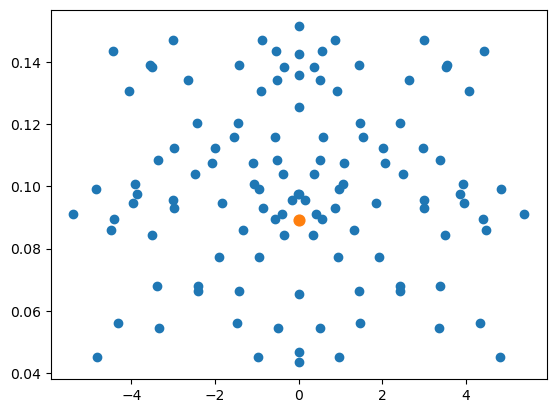

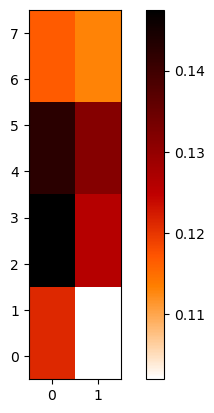

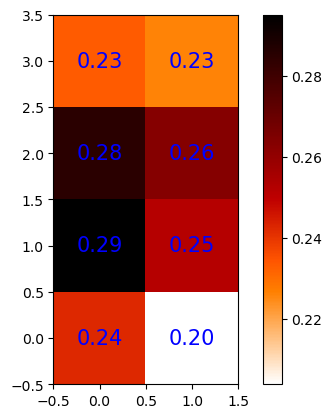

-----The results of non-Hermitian single-particle Hamiltonians-----


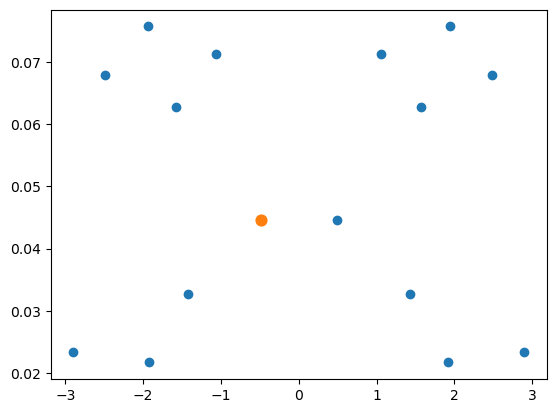

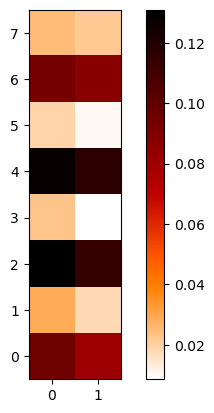

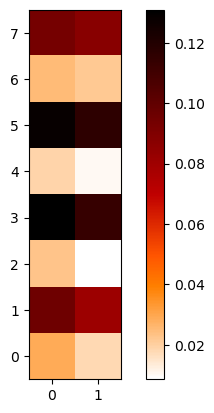

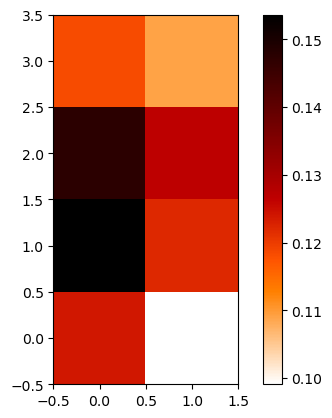

[0.09517644 0.02875181 0.01339667 0.17649288 0.00589334 0.07415563
 0.00946069 0.1589277  0.00504142 0.04905722 0.0066336  0.16496071
 0.00307231 0.1624426  0.05524911 0.00174956]
-----The results of non-Hermitian many-body Hamiltonians-----


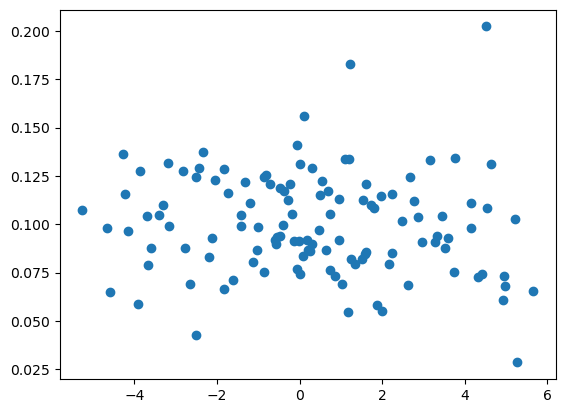

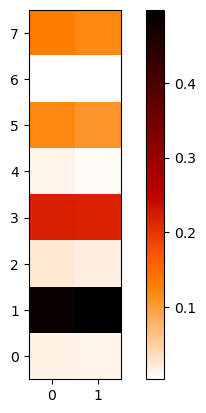

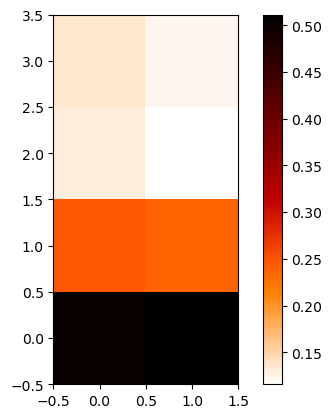

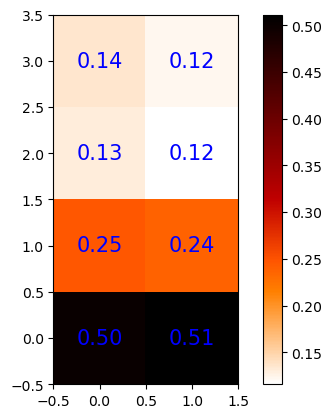

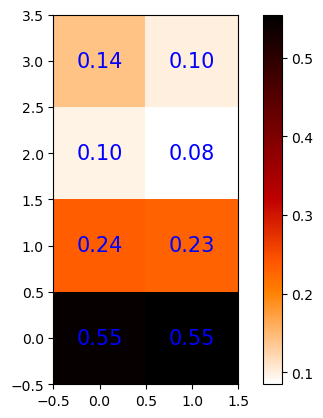

In [17]:
# without interaction
u = -1.5 # u 太大之后使topological trivial的。
gamma = 0.2
num_xsite = 2
num_ysite = 4
total_particle = 2
U = 1.
color_string = 'gist_heat_r' # 'plasma'  # 'seismic'这一个就完全使红蓝的。
QWZ1 = ParticleConservedSystem(num_xsite, num_ysite, total_particle)
QWZ1.add_onsite_term(u)
QWZ1.add_xhopping_term()
QWZ1.add_yhopping_term()
# QWZ1.add_interaction_inter(U)
QWZ1.add_NH(gamma)
ham2 = QWZ1.hamiltonian
eigval2, eigvec2 = np.linalg.eig(ham2)

ham1 = RealHam_QWZ_Dissapation(u, 1, gamma, num_xsite, num_ysite, boundary='open')
eigval, eigvec = np.linalg.eig(ham1)
eigvec = eigvec[:, np.argsort(np.abs(eigval.real))]
eigval = eigval[np.argsort(np.abs(eigval.real))]

print("-----The results of non-Hermitian multi-particle Hamiltonians-----")

eigvec2 = eigvec2[:, np.argsort(np.abs(eigval2-eigval[0]-eigval[1]))]
eigval2 = eigval2[np.argsort(np.abs(eigval2-eigval[0]-eigval[1]))]
plt.scatter(eigval2.real, eigval2.imag)
plt.scatter(eigval2[0].real, eigval2[0].imag, s=60)
plt.show()

popu_indice = QWZ1.Calcu_Occup()
popu_eig = np.zeros(QWZ1.total_mode)
for k in range(2*num_xsite*num_ysite): # 应该要加2。
    #print(temp_state[popu_indice[k]])
    popu_eig[k] = np.sum(np.abs(eigvec2[popu_indice[k],0])**2)
plt.imshow(popu_eig.reshape(num_xsite, 2*num_ysite).T, origin='lower', cmap=color_string)
plt.colorbar()
plt.show()

popu_eig = popu_eig[::2] + popu_eig[1::2]
popu_eig = popu_eig.reshape(num_xsite, num_ysite).T
plt.imshow(popu_eig, origin='lower', cmap=color_string)
# 在每个位置添加数字
for i in range(popu_eig.shape[0]):  # 遍历行
    for j in range(popu_eig.shape[1]):  # 遍历列
        plt.text(j, i, f'{popu_eig[i, j]:.2f}',  # 显示两位小数
                 ha='center', va='center', 
                 color='blue', fontsize=15)  # 调整颜色和大小以提高可读性
plt.colorbar()
plt.show()

print("-----The results of non-Hermitian single-particle Hamiltonians-----")

plt.scatter(eigval.real, eigval.imag)
plt.scatter(eigval[0].real, eigval[0].imag, s=60)
plt.show()

plt.imshow((np.abs(eigvec[:, 0])**2).reshape(num_xsite, 2*num_ysite).T, origin='lower', cmap=color_string)
plt.colorbar()
plt.show()
plt.imshow((np.abs(eigvec[:, 1])**2).reshape(num_xsite, 2*num_ysite).T, origin='lower', cmap=color_string)
plt.colorbar()
plt.show()
popu1 = np.abs(eigvec[:, 0])**2
popu1 = popu1[::2] + popu1[1::2]
plt.imshow(popu1.reshape(num_xsite, num_ysite).T, origin='lower', cmap=color_string)
plt.colorbar()
plt.show()

print((np.abs(eigvec[0])**2))

# with U interaction
u = -1.5 # u 太大之后使topological trivial的。
gamma = 0.2
num_xsite = 2
num_ysite = 4
total_particle = 2
U = 1.
QWZ1 = ParticleConservedSystem(num_xsite, num_ysite, total_particle)
QWZ1.add_onsite_term(u)
QWZ1.add_xhopping_term()
QWZ1.add_yhopping_term()
QWZ1.add_interaction_inter(U)
QWZ1.add_NH(gamma)
ham2 = QWZ1.hamiltonian
eigval2, eigvec3 = np.linalg.eig(ham2)

print("-----The results of non-Hermitian many-body Hamiltonians-----")

eigvec3 = eigvec3[:, np.argsort(np.abs(eigval2.imag))]
eigval2 = eigval2[np.argsort(np.abs(eigval2.imag))]
plt.scatter(eigval2.real, eigval2.imag)
plt.show()

popu_indice = QWZ1.Calcu_Occup()
popu_eig = np.zeros(QWZ1.total_mode)
for k in range(2*num_xsite*num_ysite): # 应该要加2。
    #print(temp_state[popu_indice[k]])
    popu_eig[k] = np.sum(np.abs(eigvec3[popu_indice[k],-1])**2)
plt.imshow(popu_eig.reshape(num_xsite, 2*num_ysite).T, origin='lower', cmap=color_string)
plt.colorbar()
plt.show()

popu_eig = popu_eig[::2] + popu_eig[1::2]
plt.imshow(popu_eig.reshape(num_xsite, num_ysite).T, origin='lower', cmap=color_string)
plt.colorbar()
plt.show()

# popu_eig = popu_eig[::2] + popu_eig[1::2]
popu_eig = popu_eig.reshape(num_xsite, num_ysite).T
plt.imshow(popu_eig, origin='lower', cmap=color_string)
# 在每个位置添加数字
for i in range(popu_eig.shape[0]):  # 遍历行
    for j in range(popu_eig.shape[1]):  # 遍历列
        plt.text(j, i, f'{popu_eig[i, j]:.2f}',  # 显示两位小数
                 ha='center', va='center', 
                 color='blue', fontsize=15)  # 调整颜色和大小以提高可读性
plt.colorbar()
plt.show()

import h5py
with h5py.File('optimization_results_particle_Interaction2.h5', 'r') as f:
    final_state = f['final_state'][:]
popu_eig = np.zeros(QWZ1.total_mode)
for k in range(2*num_xsite*num_ysite): # 应该要加2。
    #print(temp_state[popu_indice[k]])
    popu_eig[k] = np.sum(np.abs(final_state[popu_indice[k]])**2)
popu_eig = popu_eig[::2] + popu_eig[1::2]
popu_eig = popu_eig.reshape(num_xsite, num_ysite).T
plt.imshow(popu_eig, origin='lower', cmap=color_string)
# 在每个位置添加数字
for i in range(popu_eig.shape[0]):  # 遍历行
    for j in range(popu_eig.shape[1]):  # 遍历列
        plt.text(j, i, f'{popu_eig[i, j]:.2f}',  # 显示两位小数
                 ha='center', va='center', 
                 color='blue', fontsize=15)  # 调整颜色和大小以提高可读性
plt.colorbar()
plt.show()

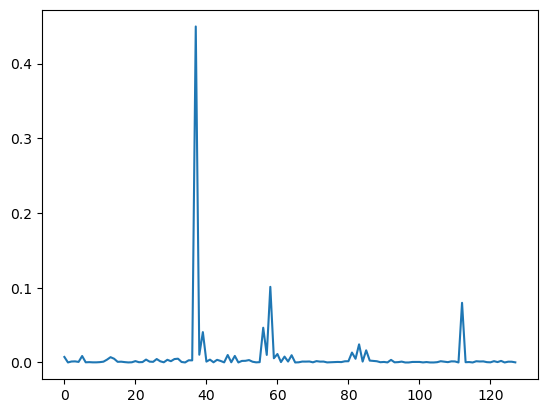

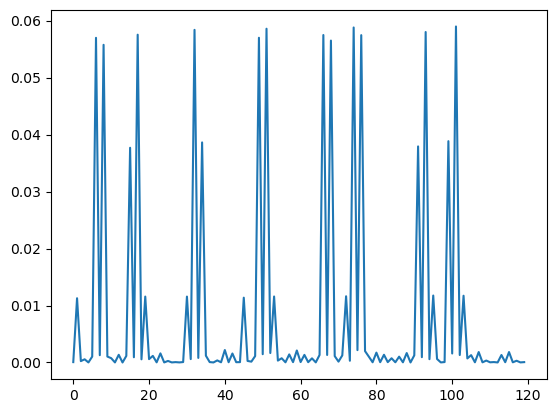

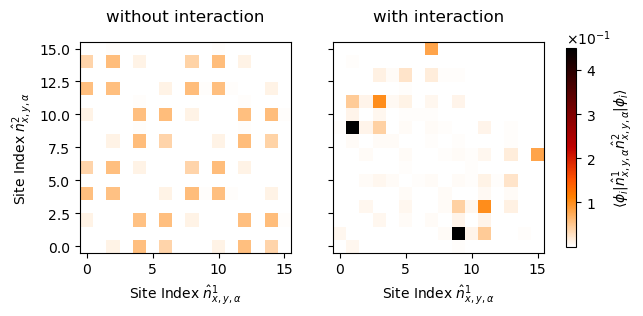

In [46]:
from matplotlib.ticker import ScalarFormatter
plt.plot(np.abs(final_state)**2)
plt.show()

plt.plot(np.abs(eigvec2[:,-1])**2)
plt.show()

num_x = 2
num_y = 4
d_indice = np.tril_indices(2*num_x*num_y, k=-1)
d_NH = np.zeros((2*num_x*num_y, 2*num_x*num_y))
d_NH_inter = np.zeros((2*num_x*num_y, 2*num_x*num_y))
d_NH[d_indice] = np.abs(eigvec2[:,-1])**2
d_NH = d_NH + d_NH.T

d_NH_inter[d_indice] = np.abs(final_state[:120])**2
d_NH_inter = d_NH_inter + d_NH_inter.T

fig, axes = plt.subplots(1,2, sharex=True, sharey=True)
vmin, vmax = np.min([np.min(np.abs(eigvec2[:,-1])**2), np.min(np.abs(final_state[:120])**2)]), np.max([np.max(np.abs(eigvec2[:,-1])**2), np.max(np.abs(final_state[:120])**2)])
img1 = axes[0].imshow(d_NH, cmap=color_string, 
        origin='lower', 
        aspect='equal', vmin=vmin,vmax=vmax # 关键修改：保证正方形
        )
img2 = axes[1].imshow(d_NH_inter, cmap=color_string, 
        origin='lower', 
        aspect='equal', vmin=vmin,vmax=vmax  # 关键修改：保证正方形
        )

titles = ['without interaction', 'with interaction']
imgs = [img1, img2]
# 科学计数法格式化器
sci_formatter = ScalarFormatter(useMathText=True)
sci_formatter.set_powerlimits((0, 0))
for ax,title in zip(axes, titles):
    # 设置标题和标签（x和y相同）
    ax.set_title(title, pad=15)
    ax.set_xlabel(r'Site Index $\hat{n}^1_{x,y,\alpha}$')
    # ax.set_ylabel(r'Site Index $\hat{n}^2_{x,y,\alpha}$')
    
    # 设置刻度
    # n = matrix.shape[0]
    # step = max(1, n//4)  # 减少刻度密度
    # ax.set_xticks(np.arange(0, n, step), np.arange(1, n, step))
    # ax.set_yticks(np.arange(0, n, step), np.arange(1, n, step))

axes[0].set_ylabel(r'Site Index $\hat{n}^2_{x,y,\alpha}$')
# 添加colorbar（使用科学计数法）
cbar = fig.colorbar(img1, ax=axes.ravel().tolist(), fraction=0.02, pad=0.35)
cbar.formatter = sci_formatter
cbar.update_normal(img1)
cbar.ax.yaxis.set_offset_position('left')  # 科学计数法偏移位置
cbar.set_label(r'$\langle \phi_i \vert \hat{n}^1_{x,y,\alpha} \hat{n}^2_{x,y,\alpha} \vert \phi_i \rangle$', rotation=90, labelpad=10)
plt.subplots_adjust(wspace=0.2, right=0.85)  # 调整 wspace 控制子图间距

plt.show()

## 单体

<KeysViewHDF5 ['1', '2', '3', 'final state', 'target state']>
0.14608664001998029
0.06838151816770677
0.0015409032949482704


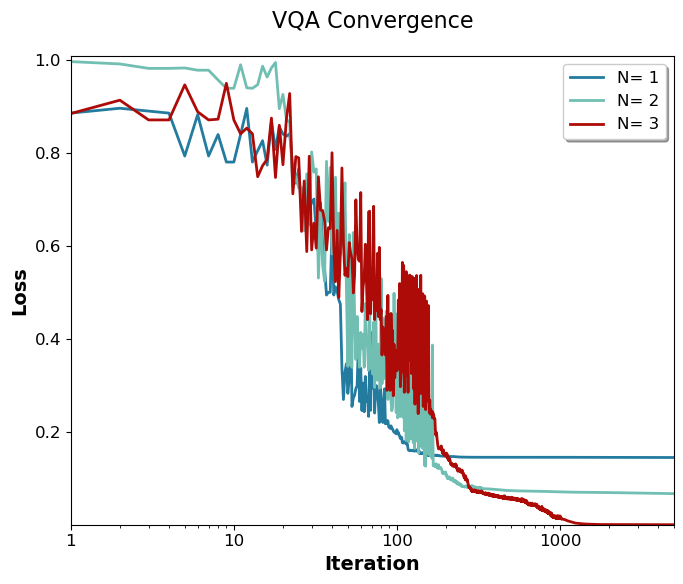

[ 0.22751688-0.22979006j  0.0101539 +0.17210391j  0.2036893 -0.28607288j
  0.08743599+0.11789727j  0.17371772-0.31778235j  0.12889408+0.02874819j
  0.1536625 -0.25988725j  0.14373627-0.06222233j  0.18463219-0.19798214j
 -0.11529412+0.0580674j   0.18977039-0.29506755j -0.09295755-0.00106019j
  0.18451768-0.28304383j -0.05261013-0.08738903j  0.14310341-0.26375227j
  0.00361453-0.14232504j] [ 0.30372187+0.05412455j -0.13476257+0.10291189j  0.36189877+0.j
 -0.04694574+0.14313259j  0.35709845-0.03099167j  0.04884073+0.12818761j
  0.30320084-0.03584704j  0.13632859+0.08090104j  0.28210615+0.03726055j
 -0.12121564-0.05831257j  0.33669981-0.01163628j -0.04605964-0.08014327j
  0.34042453-0.02100757j  0.03636227-0.09544483j  0.29455428-0.02083502j
  0.12199835-0.08253635j]


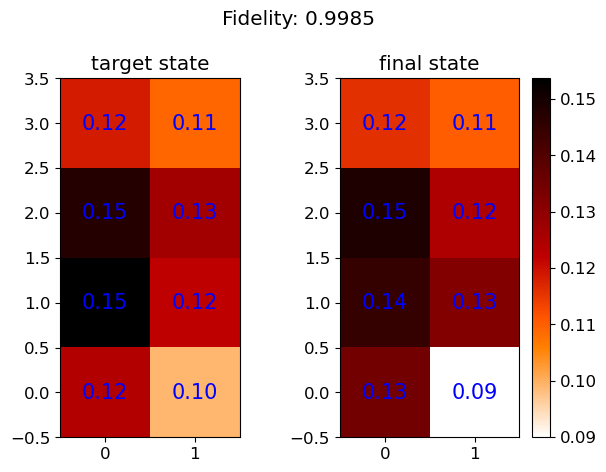

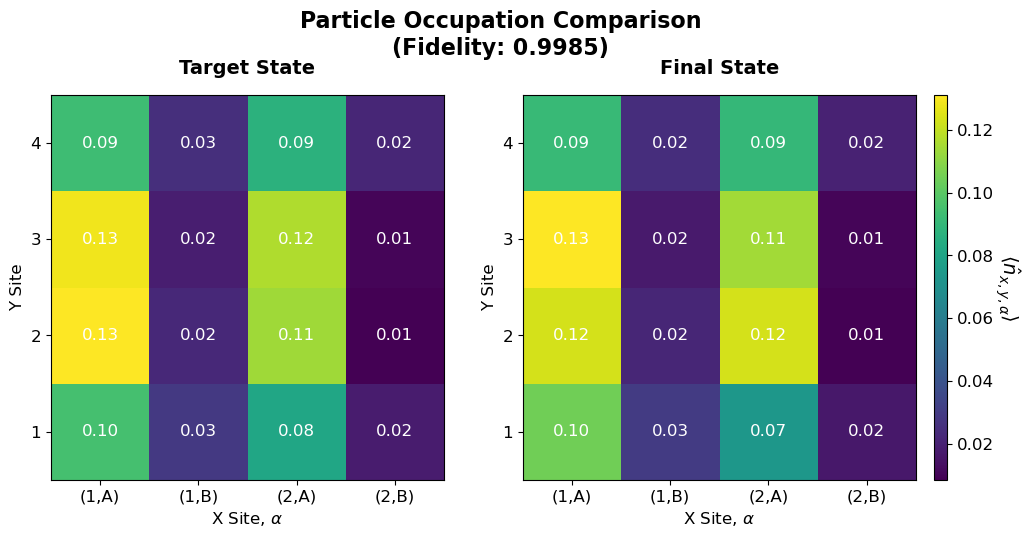

In [48]:
import h5py
import matplotlib.pyplot as plt
color_string = ['#237B9F', '#71BFB2', '#AD0B08', '#EC817E', '#FEE066']
with h5py.File('VQE_SingleExcitation.h5', 'r') as f:
    # 写入一个 NumPy 数组
    print(f.keys())
    # loss = f['loss']
    final_state = f['final state'][:]
    target_state = f['target state'][:]


    # 设置图形样式
    # plt.style.use('seaborn')  # 使用seaborn风格
    plt.style.use('default')  # 使用seaborn风格
    plt.rcParams.update({
        'font.size': 12,          # 全局字体大小
        'axes.labelsize': 14,     # 坐标轴标签字体
        'xtick.labelsize': 12,    # x轴刻度字体
        'ytick.labelsize': 12,    # y轴刻度字体
        'legend.fontsize': 12     # 图例字体
    })

    fig, ax = plt.subplots(figsize=(7, 6))  # 创建画布

    for i in range(1, 4):
        # 绘制曲线，使用指定颜色和标签
        ax.plot(range(1,len(f[str(i)][:])+1), f[str(i)][:], 
                color=color_string[i-1], 
                label=f'N= {i}',
                linewidth=2)
        print(f[str(i)][-1])
        fidelity = 1-f[str(i)][-1]

    # 设置坐标轴范围
    ax.set_xlim(1, 5000+1)  # 横轴范围
    ax.set_ylim(min([min(f[str(i)][:]) for i in range(1,4)])*0.99, 1.01)  # 纵轴自动适应

    # 设置刻度（x轴使用对数刻度更清晰）
    ax.set_xscale('log')  # 对数刻度适合大范围数据
    ax.xaxis.set_major_formatter(plt.ScalarFormatter())  # 禁用科学计数法

    # 添加网格和标签
    # ax.grid(True, linestyle='--', alpha=0.6)
    ax.set_xlabel('Iteration', fontweight='bold')
    ax.set_ylabel('Loss', fontweight='bold')
    ax.set_title('VQA Convergence', pad=20, fontsize=16)

    # 优化图例位置
    ax.legend(loc='upper right', frameon=True, shadow=True)

    # 自动调整布局
    plt.tight_layout()
    plt.show()

import numpy as np
fig, ax = plt.subplots(1,2)
u = -1.5 # u 太大之后使topological trivial的。
gamma = 0.2
num_xsite = 2
num_ysite = 4
total_particle = 2
U = 1.
color_string = 'gist_heat_r' # 'plasma'  # 'seismic'这一个就完全使红蓝的。

print(final_state, target_state)

popu_eig1 = np.zeros(16)
for k in range(2*num_xsite*num_ysite): # 应该要加2。
    #print(temp_state[popu_indice[k]])
    popu_eig1[k] = np.sum(np.abs(final_state[k])**2)
popu_eig1 = popu_eig1[::2] + popu_eig1[1::2]
popu_eig2 = np.zeros(16)
for k in range(2*num_xsite*num_ysite): # 应该要加2。
    #print(temp_state[popu_indice[k]])
    popu_eig2[k] = np.sum(np.abs(target_state[k])**2)
popu_eig2 = popu_eig2[::2] + popu_eig2[1::2]
vmin, vmax = np.min([np.min(popu_eig1), np.min(popu_eig2)]), np.max([np.max(popu_eig1), np.max(popu_eig2)])

im1 = ax[1].imshow(popu_eig1.reshape(num_xsite, num_ysite).T, origin='lower', cmap=color_string, vmin=vmin,vmax=vmax)
# plt.colorbar(im1, ax=ax[0])  # 为第一个子图添加 colorbar
ax[1].set_title('final state')

im2 = ax[0].imshow(popu_eig2.reshape(num_xsite, num_ysite).T, origin='lower', cmap=color_string, vmin=vmin,vmax=vmax)

popu_eig2 = popu_eig2.reshape(num_xsite, num_ysite).T
for i in range(popu_eig2.shape[0]):  # 遍历行
    for j in range(popu_eig2.shape[1]):  # 遍历列
        ax[0].text(j, i, f'{popu_eig2[i, j]:.2f}',  # 显示两位小数
                 ha='center', va='center', 
                 color='blue', fontsize=15)  # 调整颜色和大小以提高可读性
popu_eig1 = popu_eig1.reshape(num_xsite, num_ysite).T
for i in range(popu_eig1.shape[0]):  # 遍历行
    for j in range(popu_eig1.shape[1]):  # 遍历列
        ax[1].text(j, i, f'{popu_eig1[i, j]:.2f}',  # 显示两位小数
                 ha='center', va='center', 
                 color='blue', fontsize=15)  # 调整颜色和大小以提高可读性
        
ax[0].set_title('target state')
fig.suptitle(f'Fidelity: {fidelity:.4f}')
plt.colorbar(im2, ax=ax[1])  # 为第一个子图添加 colorbar
# plt.colorbar()
plt.tight_layout()  # 调整子图间距，防止重叠
plt.show()



import numpy as np
import matplotlib.pyplot as plt
from matplotlib import ticker

# 参数设置
u = -1.5
gamma = 0.2
num_xsite = 2
num_ysite = 4
total_particle = 2
U = 1.

# 高级颜色映射 (改用更科学的配色)
color_map = 'viridis'  # 替代gist_heat_r，更好的亮度线性变化
text_color = 'white'   # 根据背景自动调整的文字颜色

# 创建图形
fig, ax = plt.subplots(1, 2, figsize=(12, 5), 
                      gridspec_kw={'width_ratios': [1, 1], 'wspace': 0.2})

# 计算粒子占据数
def calculate_occupation(state):
    popu_eig = np.zeros(2*num_xsite*num_ysite)
    for k in range(2*num_xsite*num_ysite):
        popu_eig[k] = np.sum(np.abs(state[k])**2)
    #return popu_eig[::2] + popu_eig[1::2]
    result = np.zeros((4,4))
    result[0]= popu_eig[:8:2]
    result[1]= popu_eig[1:8:2]
    result[2]= popu_eig[8::2]
    result[3]= popu_eig[9::2]
    return result

# popu_eig1 = calculate_occupation(final_state).reshape(num_xsite, num_ysite).T
# popu_eig2 = calculate_occupation(target_state).reshape(num_xsite, num_ysite).T
popu_eig1 = calculate_occupation(final_state).T
popu_eig2 = calculate_occupation(target_state).T

# 统一色标范围
vmin = min(np.min(popu_eig1), np.min(popu_eig2))
vmax = max(np.max(popu_eig1), np.max(popu_eig2))

# 绘制第一个子图 (final state)
im1 = ax[1].imshow(popu_eig1, origin='lower', cmap=color_map,
                  vmin=vmin, vmax=vmax, aspect='auto')
ax[1].set_title('Final State', pad=15, fontsize=14, fontweight='bold')

# 添加数值标签
for i in range(popu_eig1.shape[0]):
    for j in range(popu_eig1.shape[1]):
        ax[1].text(j, i, f'{popu_eig1[i, j]:.2f}',
                 ha='center', va='center',
                 color=text_color, fontsize=12)

# 绘制第二个子图 (target state)
im2 = ax[0].imshow(popu_eig2, origin='lower', cmap=color_map,
                  vmin=vmin, vmax=vmax, aspect='auto')
ax[0].set_title('Target State', pad=15, fontsize=14, fontweight='bold')

for i in range(popu_eig2.shape[0]):
    for j in range(popu_eig2.shape[1]):
        ax[0].text(j, i, f'{popu_eig2[i, j]:.2f}',
                 ha='center', va='center',
                 color=text_color, fontsize=12)

# 添加colorbar (共享色标)
cbar = fig.colorbar(im2, ax=ax, orientation='vertical', 
                   fraction=0.05, pad=0.02, aspect=30)
cbar.set_label(r'$\langle \hat{n}_{x,y,\alpha} \rangle$', rotation=270, labelpad=20)

# 设置坐标轴
for a in ax:
    a.set_xticks(np.arange(num_ysite))
    a.set_yticks(np.arange(num_xsite))
    a.set_xlabel(r'X Site, $\alpha$', fontsize=12)
    a.set_ylabel('Y Site', fontsize=12)
    a.set_xticks([0,1,2,3])  # 设置刻度位置
    a.set_xticklabels(['(1,A)', '(1,B)', '(2,A)', '(2,B)'])  # 设置刻度标签
    a.set_yticks([0,1,2,3])  # 设置刻度位置
    a.set_yticklabels(['1', '2', '3', '4'])  # 设置刻度标签

    a.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
    a.yaxis.set_major_locator(ticker.MaxNLocator(integer=True))

# 添加主标题
fig.suptitle(f'Particle Occupation Comparison\n(Fidelity: {fidelity:.4f})', 
             y=1.05, fontsize=16, fontweight='bold')

# 调整布局
# plt.tight_layout()
plt.show()

## 两体

<KeysViewHDF5 ['1', '2', '3', '4', '5', 'final_state', 'target_state']>
0.4863988450053268 15000
0.3031018842443026 15000
0.21038665206601825 15000
0.177706388724595 15000
0.09662806055998507 15000


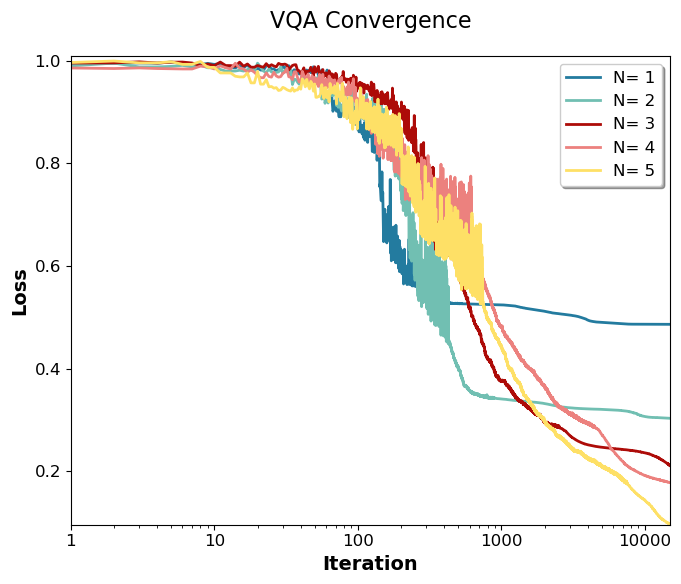

[ 1.79778073e-02-6.75135333e-02j  1.48346370e-02-2.91613298e-02j
 -1.97477868e-03+2.17287530e-02j  8.60761262e-03+1.97836867e-02j
  1.55209435e-02+4.34102175e-02j -2.86015850e-02+3.75329531e-02j
 -1.33571587e-02+1.90254073e-02j -5.16716863e-03-2.36355297e-02j
  2.19002411e-03+5.90482253e-03j  2.40360074e-03-1.25161881e-02j
 -8.11051691e-03+6.77391365e-03j  1.16249001e-02-6.03691822e-03j
 -4.23979840e-03-9.18828327e-03j  7.86339782e-03+1.09140552e-03j
  1.34645671e-02+9.88844220e-04j  1.53805274e-02+2.53898576e-03j
 -2.04097724e-03+1.65281041e-02j -2.21961817e-03+9.97396041e-03j
 -3.75137177e-03+4.66399031e-03j -2.11628114e-02-7.46651664e-04j
 -6.23395753e-03-4.22644445e-03j  2.66215682e-03-1.04579646e-02j
 -2.44806903e-03-2.72668972e-04j  2.88650646e-03-5.60086364e-03j
 -3.69429993e-02+3.40227190e-02j -2.53535559e-02+9.83231589e-03j
 -4.00760455e-02-5.35624811e-02j -4.06918409e-02-1.54176634e-02j
  3.52624925e-02+2.50979631e-02j -1.78027302e-02+1.91421070e-03j
  2.62977130e-02+8.736274

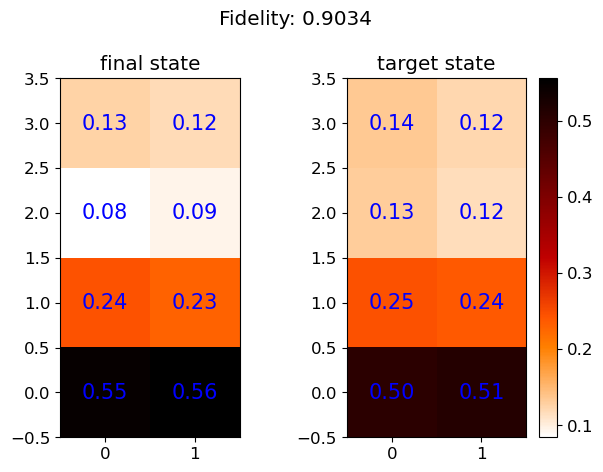

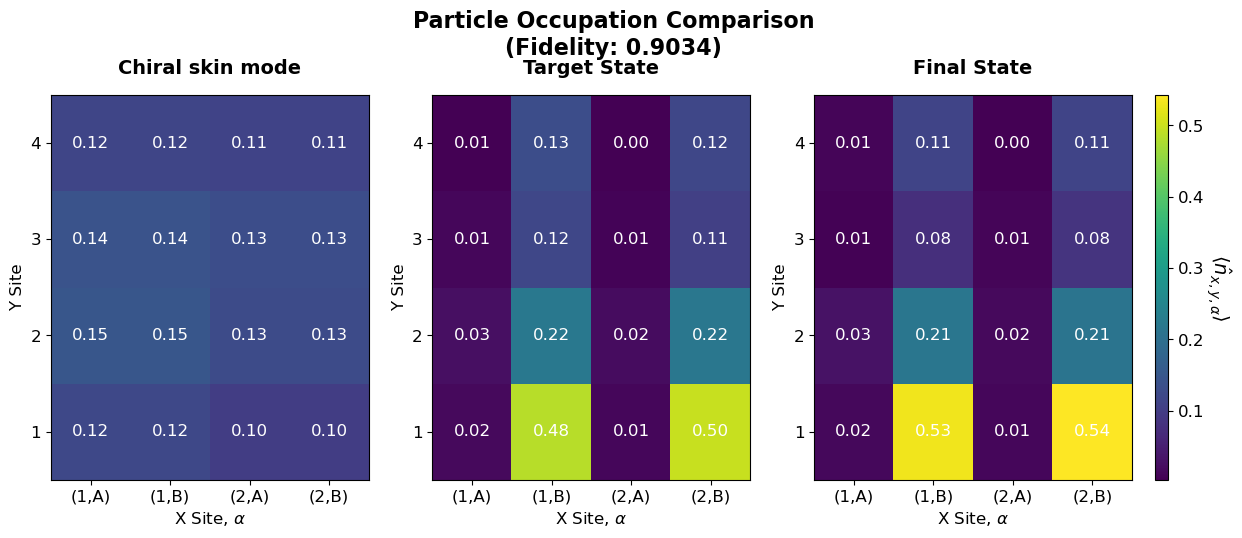

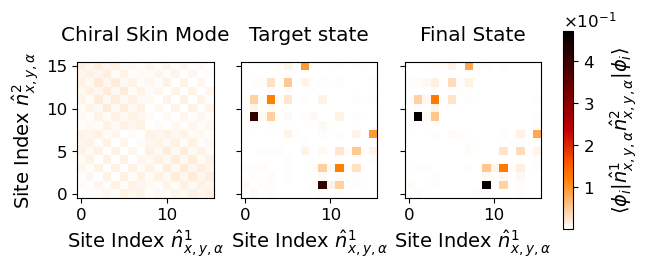

In [6]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
color_string = ['#237B9F', '#71BFB2', '#AD0B08', '#EC817E', '#FEE066']

with h5py.File('optimization_results_particle_Interaction.h5', 'r') as f:
    # 写入一个 NumPy 数组
    print(f.keys())
    # loss = f['loss']
    final_state = f['final_state'][:]
    target_state = f['target_state'][:]


    # 设置图形样式
    # plt.style.use('seaborn')  # 使用seaborn风格
    plt.style.use('default')  # 使用seaborn风格
    plt.rcParams.update({
        'font.size': 12,          # 全局字体大小
        'axes.labelsize': 14,     # 坐标轴标签字体
        'xtick.labelsize': 12,    # x轴刻度字体
        'ytick.labelsize': 12,    # y轴刻度字体
        'legend.fontsize': 12     # 图例字体
    })

    fig, ax = plt.subplots(figsize=(7, 6))  # 创建画布

    for i in range(1, 6):
        # 绘制曲线，使用指定颜色和标签
        ax.plot(range(1,len(f[str(i)][:])+1), f[str(i)][:], 
                color=color_string[i-1], 
                label=f'N= {i}',
                linewidth=2)
        print(f[str(i)][-1], len(f[str(i)][:]))
        fidelity = 1-f[str(i)][-1]

    # 设置坐标轴范围
    ax.set_xlim(1, len(f[str(i)][:])+1)  # 横轴范围
    ax.set_ylim(min([min(f[str(i)][:]) for i in range(1,6)])*0.99, 1.01)  # 纵轴自动适应

    # 设置刻度（x轴使用对数刻度更清晰）
    ax.set_xscale('log')  # 对数刻度适合大范围数据
    ax.xaxis.set_major_formatter(plt.ScalarFormatter())  # 禁用科学计数法

    # 添加网格和标签
    # ax.grid(True, linestyle='--', alpha=0.6)
    ax.set_xlabel('Iteration', fontweight='bold')
    ax.set_ylabel('Loss', fontweight='bold')
    ax.set_title('VQA Convergence', pad=20, fontsize=16)

    # 优化图例位置
    ax.legend(loc='upper right', frameon=True, shadow=True)

    # 自动调整布局
    plt.tight_layout()
    plt.show()

fig, ax = plt.subplots(1,2)
u = -1.5 # u 太大之后使topological trivial的。
gamma = 0.2
num_xsite = 2
num_ysite = 4
total_particle = 2
U = 1.
ham1 = RealHam_QWZ_Dissapation(u, 1, gamma, num_xsite, num_ysite, boundary='open')
eigval, eigvec = np.linalg.eig(ham1)
eigvec = eigvec[:, np.argsort(np.abs(eigval.real))]
eigval = eigval[np.argsort(np.abs(eigval.real))]

# without interaction
QWZ1 = ParticleConservedSystem(num_xsite, num_ysite, total_particle)
QWZ1.add_onsite_term(u)
QWZ1.add_xhopping_term()
QWZ1.add_yhopping_term()
# QWZ1.add_interaction_inter(U)
QWZ1.add_NH(gamma)
ham2_NH = QWZ1.hamiltonian
eigval2_NH, eigvec2_NH = np.linalg.eig(ham2_NH)
eigvec2_NH = eigvec2_NH[:, np.argsort(np.abs(eigval2_NH-eigval[0]-eigval[1]))]
eigval2_NH = eigval2_NH[np.argsort(np.abs(eigval2_NH-eigval[0]-eigval[1]))]

# with interaction
QWZ1 = ParticleConservedSystem(num_xsite, num_ysite, total_particle)
QWZ1.add_onsite_term(u)
QWZ1.add_xhopping_term()
QWZ1.add_yhopping_term()
QWZ1.add_interaction_inter(U)
QWZ1.add_NH(gamma)
ham2_NHMany = QWZ1.hamiltonian
eigval2_NHMany, eigvec2_NHMany = np.linalg.eig(ham2_NHMany)
eigvec2_NHMany = eigvec2_NHMany[:, np.argsort((eigval2_NHMany.imag))]
eigval2_NHMany = eigval2_NHMany[np.argsort((eigval2_NHMany.imag))]
# indices
popu_indice = QWZ1.Calcu_Occup()

color_string = 'gist_heat_r' # 'plasma'  # 'seismic'这一个就完全使红蓝的。

print(final_state, target_state)
# 计算粒子占据数
def calculate_occupation(state):
    popu_eig = np.zeros(2*num_xsite*num_ysite)
    for k in range(2*num_xsite*num_ysite):
        popu_eig[k] = np.sum(np.abs(state[popu_indice[k]])**2)
    #return popu_eig[::2] + popu_eig[1::2]
    result = np.zeros((4,4))
    result[0]= popu_eig[:8:2]
    result[1]= popu_eig[1:8:2]
    result[2]= popu_eig[8::2]
    result[3]= popu_eig[9::2]
    return result


popu_eig_NH = np.zeros(16)
for k in range(2*num_xsite*num_ysite): # 应该要加2。
    #print(temp_state[popu_indice[k]])
    popu_eig_NH[k] = np.sum(np.abs(final_state[popu_indice[k]])**2)
popu_eig_NH = popu_eig_NH[::2] + popu_eig_NH[1::2]
popu_eig_NHMany = np.zeros(16)
for k in range(2*num_xsite*num_ysite): # 应该要加2。
    #print(temp_state[popu_indice[k]])
    popu_eig_NHMany[k] = np.sum(np.abs(target_state[popu_indice[k]])**2)
popu_eig_NHMany = popu_eig_NHMany[::2] + popu_eig_NHMany[1::2]
vmin, vmax = np.min([np.min(popu_eig_NH), np.min(popu_eig_NHMany)]), np.max([np.max(popu_eig_NH), np.max(popu_eig_NHMany)])

im1 = ax[0].imshow(popu_eig_NH.reshape(num_xsite, num_ysite).T, origin='lower', cmap=color_string, vmin=vmin,vmax=vmax)
# plt.colorbar(im1, ax=ax[0])  # 为第一个子图添加 colorbar
ax[0].set_title('final state')

im2 = ax[1].imshow(popu_eig_NHMany.reshape(num_xsite, num_ysite).T, origin='lower', cmap=color_string, vmin=vmin,vmax=vmax)

popu_eig_NHMany = popu_eig_NHMany.reshape(num_xsite, num_ysite).T
for i in range(popu_eig_NHMany.shape[0]):  # 遍历行
    for j in range(popu_eig_NHMany.shape[1]):  # 遍历列
        ax[1].text(j, i, f'{popu_eig_NHMany[i, j]:.2f}',  # 显示两位小数
                 ha='center', va='center', 
                 color='blue', fontsize=15)  # 调整颜色和大小以提高可读性
popu_eig_NH = popu_eig_NH.reshape(num_xsite, num_ysite).T
for i in range(popu_eig_NH.shape[0]):  # 遍历行
    for j in range(popu_eig_NH.shape[1]):  # 遍历列
        ax[0].text(j, i, f'{popu_eig_NH[i, j]:.2f}',  # 显示两位小数
                 ha='center', va='center', 
                 color='blue', fontsize=15)  # 调整颜色和大小以提高可读性
        
ax[1].set_title('target state')
fig.suptitle(f'Fidelity: {fidelity:.4f}')
plt.colorbar(im2, ax=ax[1])  # 为第一个子图添加 colorbar
# plt.colorbar()
plt.tight_layout()  # 调整子图间距，防止重叠
plt.show()



import numpy as np
import matplotlib.pyplot as plt
from matplotlib import ticker

# 参数设置
u = -1.5
gamma = 0.2
num_xsite = 2
num_ysite = 4
total_particle = 2
U = 1.

# 高级颜色映射 (改用更科学的配色)
color_map = 'viridis'  # 替代gist_heat_r，更好的亮度线性变化
text_color = 'white'   # 根据背景自动调整的文字颜色

# 创建图形
fig, ax = plt.subplots(1, 3, figsize=(15, 5), 
                      gridspec_kw={'width_ratios': [1, 1, 1], 'wspace': 0.2})

# 计算粒子占据数
def calculate_occupation(state):
    popu_eig = np.zeros(2*num_xsite*num_ysite)
    for k in range(2*num_xsite*num_ysite):
        popu_eig[k] = np.sum(np.abs(state[popu_indice[k]])**2)
    #return popu_eig[::2] + popu_eig[1::2]
    result = np.zeros((4,4))
    result[0]= popu_eig[:8:2]
    result[1]= popu_eig[1:8:2]
    result[2]= popu_eig[8::2]
    result[3]= popu_eig[9::2]
    return result

# popu_eig1 = calculate_occupation(final_state).reshape(num_xsite, num_ysite).T
# popu_eig2 = calculate_occupation(target_state).reshape(num_xsite, num_ysite).T
popu_eig_NH = calculate_occupation(eigvec2_NH[:,0]).T
popu_eig_NHMany = calculate_occupation(target_state).T
popu_eig_final = calculate_occupation(final_state).T

# 统一色标范围
vmin = min(np.min(popu_eig_NH), np.min(popu_eig_NHMany), np.min(popu_eig_final))
vmax = max(np.max(popu_eig_NH), np.max(popu_eig_NHMany), np.max(popu_eig_final))

# 绘制第一个子图 (final state)
im1 = ax[0].imshow(popu_eig_NH, origin='lower', cmap=color_map,
                  vmin=vmin, vmax=vmax, aspect='auto')
ax[0].set_title('Chiral skin mode', pad=15, fontsize=14, fontweight='bold')

# 添加数值标签
for i in range(popu_eig_NH.shape[0]):
    for j in range(popu_eig_NH.shape[1]):
        ax[0].text(j, i, f'{popu_eig_NH[i, j]:.2f}',
                 ha='center', va='center',
                 color=text_color, fontsize=12)

# 绘制第二个子图 (target state)
im2 = ax[1].imshow(popu_eig_NHMany, origin='lower', cmap=color_map,
                  vmin=vmin, vmax=vmax, aspect='auto')
ax[1].set_title('Target State', pad=15, fontsize=14, fontweight='bold')

for i in range(popu_eig_NHMany.shape[0]):
    for j in range(popu_eig_NHMany.shape[1]):
        ax[1].text(j, i, f'{popu_eig_NHMany[i, j]:.2f}',
                 ha='center', va='center',
                 color=text_color, fontsize=12)

# 绘制第二个子图 (target state)
im2 = ax[2].imshow(popu_eig_final, origin='lower', cmap=color_map,
                  vmin=vmin, vmax=vmax, aspect='auto')
ax[2].set_title('Final State', pad=15, fontsize=14, fontweight='bold')

for i in range(popu_eig_final.shape[0]):
    for j in range(popu_eig_final.shape[1]):
        ax[2].text(j, i, f'{popu_eig_final[i, j]:.2f}',
                 ha='center', va='center',
                 color=text_color, fontsize=12)

# 添加colorbar (共享色标)
cbar = fig.colorbar(im2, ax=ax, orientation='vertical', 
                   fraction=0.05, pad=0.02, aspect=30)
cbar.set_label(r'$\langle \hat{n}_{x,y,\alpha} \rangle$', rotation=270, labelpad=20)

# 设置坐标轴
for a in ax:
    a.set_xticks(np.arange(num_ysite))
    a.set_yticks(np.arange(num_xsite))
    a.set_xlabel(r'X Site, $\alpha$', fontsize=12)
    a.set_ylabel('Y Site', fontsize=12)
    a.set_xticks([0,1,2,3])  # 设置刻度位置
    a.set_xticklabels(['(1,A)', '(1,B)', '(2,A)', '(2,B)'])  # 设置刻度标签
    a.set_yticks([0,1,2,3])  # 设置刻度位置
    a.set_yticklabels(['1', '2', '3', '4'])  # 设置刻度标签

    a.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
    a.yaxis.set_major_locator(ticker.MaxNLocator(integer=True))

# 添加主标题
fig.suptitle(f'Particle Occupation Comparison\n(Fidelity: {fidelity:.4f})', 
             y=1.05, fontsize=16, fontweight='bold')

# 调整布局
# plt.tight_layout()
plt.show()



# 关联函数
num_x = 2
num_y = 4
d_indice = np.tril_indices(2*num_x*num_y, k=-1)
d_NH = np.zeros((2*num_x*num_y, 2*num_x*num_y))
d_NHMany = np.zeros((2*num_x*num_y, 2*num_x*num_y))
d_final_state = np.zeros((2*num_x*num_y, 2*num_x*num_y))
d_NH[d_indice] = np.abs(eigvec2_NH[:, 0])**2
d_NH = d_NH + d_NH.T

d_NHMany[d_indice] = np.abs(target_state[:120,0])**2
d_NHMany = d_NHMany + d_NHMany.T
d_final_state[d_indice] = np.abs(final_state[:120])**2
d_final_state = d_final_state + d_final_state.T

fig, axes = plt.subplots(1,3, sharex=True, sharey=True)
vmin, vmax = np.min([np.min(np.abs(eigvec2_NH[:,0])**2), np.min(np.abs(target_state[:120, 0])**2), np.min(np.abs(final_state[:120])**2)]), np.max([np.max(np.abs(eigvec2_NH[:,0])**2), np.max(np.abs(target_state[:120,0])**2), np.max(np.abs(final_state[:120])**2)])
img1 = axes[0].imshow(d_NH, cmap=color_string, 
        origin='lower', 
        aspect='equal', vmin=vmin,vmax=vmax # 关键修改：保证正方形
        )
img2 = axes[1].imshow(d_NHMany, cmap=color_string, 
        origin='lower', 
        aspect='equal', vmin=vmin,vmax=vmax  # 关键修改：保证正方形
        )
img2 = axes[2].imshow(d_final_state, cmap=color_string, 
        origin='lower', 
        aspect='equal', vmin=vmin,vmax=vmax  # 关键修改：保证正方形
        )

titles = ['Chiral Skin Mode', 'Target state', 'Final State']
imgs = [img1, img2]
# 科学计数法格式化器
sci_formatter = ScalarFormatter(useMathText=True)
sci_formatter.set_powerlimits((0, 0))
for ax,title in zip(axes, titles):
    # 设置标题和标签（x和y相同）
    ax.set_title(title, pad=15)
    ax.set_xlabel(r'Site Index $\hat{n}^1_{x,y,\alpha}$')
    # ax.set_ylabel(r'Site Index $\hat{n}^2_{x,y,\alpha}$')
    
    # 设置刻度
    # n = matrix.shape[0]
    # step = max(1, n//4)  # 减少刻度密度
    # ax.set_xticks(np.arange(0, n, step), np.arange(1, n, step))
    # ax.set_yticks(np.arange(0, n, step), np.arange(1, n, step))

axes[0].set_ylabel(r'Site Index $\hat{n}^2_{x,y,\alpha}$')
# 添加colorbar（使用科学计数法）
cbar = fig.colorbar(img1, ax=axes.ravel().tolist(), fraction=0.02, pad=0.35)
cbar.formatter = sci_formatter
cbar.update_normal(img1)
cbar.ax.yaxis.set_offset_position('left')  # 科学计数法偏移位置
cbar.set_label(r'$\langle \phi_i \vert \hat{n}^1_{x,y,\alpha} \hat{n}^2_{x,y,\alpha} \vert \phi_i \rangle$', rotation=90, labelpad=10)
plt.subplots_adjust(wspace=0.2, right=0.85)  # 调整 wspace 控制子图间距

plt.show()